# 15. Comparación probabilística — SARIMAX, LSTM, TFT + covariables y GRU Bayesiana

## Objetivo
Comparar, sobre el **mismo periodo de test (2025-08-01 a 2026-07-31)** y únicamente en horizontes **1 y 7 días**, cuatro enfoques representativos:

1. **SARIMAX(2,0,2)(1,0,1,7)** con covariables — incertidumbre estadística nativa.
2. **LSTM cuantílica** — intervalos P10/P50/P90 aprendidos con pinball loss.
3. **TFT + covariables (GluonTS)** — cuantiles probabilísticos nativos.
4. **GRU Bayesiana** — muestreo Monte Carlo de pesos bayesianos.

Se incluye **Persistencia** (`P̂[t+h] = P[t]`) como benchmark puntual.

## Principios metodológicos
- No se usa h=30 en esta comparación.
- Todos los resultados se alinean por **fecha objetivo real**.
- Las bandas P10–P90 no tienen idéntica interpretación entre familias; se documenta su origen.
- `uncertainty-toolbox` se usa como **marco común de evaluación**, no como generador universal de incertidumbre.
- Para los modelos que entregan cuantiles, se construye una desviación estándar **gaussiana equivalente** a partir de P10–P90 únicamente para las métricas de UCT que requieren `y_std`.
- La cobertura P10–P90 y el ancho del intervalo se calculan directamente, sin asumir normalidad.
- El test se usa solo para evaluación final.

In [1]:
# Si es la primera vez que ejecutas este notebook, instala UCT en el entorno tesis-bolsa:
# %pip install uncertainty-toolbox

from pathlib import Path
import os, random, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 333
random.seed(SEED)
np.random.seed(SEED)

def encontrar_raiz_repo():
    actual = Path.cwd().resolve()
    for p in [actual, *actual.parents]:
        if (p / ".git").exists() or ((p / "data" / "processed").exists() and (p / "notebooks").exists()):
            return p
    raise FileNotFoundError("No se encontró la raíz del proyecto tesis-bolsa.")

ROOT = encontrar_raiz_repo()
DATA = ROOT / "data" / "processed"
MODELS = ROOT / "models"
REPORTS = ROOT / "reports" / "comparacion_probabilistica"
REPORTS.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

TEST_START = pd.Timestamp("2025-08-01")
TEST_END   = pd.Timestamp("2026-07-31")
HORIZONTES = [1, 7]
COVARIABLES = ["gen_termica", "ONI", "aportes_energia_gwh"]

print("Raíz:", ROOT)
print("Reportes:", REPORTS)

Raíz: /Users/maguverm/Documents/tesis-bolsa
Reportes: /Users/maguverm/Documents/tesis-bolsa/reports/comparacion_probabilistica


In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)

# TFT de GluonTS se mantiene en CPU por compatibilidad con la implementación original.
# Permitimos que PyTorch use los núcleos CPU disponibles para ese entrenamiento.
N_CPU = os.cpu_count() or 1
torch.set_num_threads(N_CPU)

if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)
torch.manual_seed(SEED)

print("Dispositivo redes PyTorch:", device)
print("Hilos CPU disponibles para TFT:", N_CPU)

Dispositivo redes PyTorch: mps
Hilos CPU disponibles para TFT: 18


In [3]:
df = pd.read_parquet(DATA / "dataset_consolidado.parquet").copy()
df.index = pd.to_datetime(df.index)
df = df.sort_index()

faltantes = [c for c in ["precio_bolsa", *COVARIABLES] if c not in df.columns]
if faltantes:
    raise KeyError(f"Faltan columnas necesarias: {faltantes}")

train_df = df[df.index < TEST_START].copy()
test_df  = df[(df.index >= TEST_START) & (df.index <= TEST_END)].copy()

print("Train:", train_df.index.min().date(), "→", train_df.index.max().date(), len(train_df))
print("Test: ", test_df.index.min().date(), "→", test_df.index.max().date(), len(test_df))

Train: 2013-01-01 → 2025-07-31 4595
Test:  2025-08-01 → 2026-07-31 365


## 1. Funciones comunes

Cada modelo se normaliza al mismo formato:

`fecha | real | pred | p10 | p50 | p90 | std`

`std` es la desviación predictiva nativa cuando existe; para modelos cuantílicos se usa una desviación gaussiana equivalente derivada de P10–P90 para poder aplicar las métricas de `uncertainty-toolbox` que exigen media y desviación estándar.

In [4]:
from sklearn.metrics import r2_score, median_absolute_error, max_error

Z90 = 1.2815515655446004  # cuantil N(0,1) correspondiente a 0.90

def std_equivalente_p10_p90(p10, p90, piso=1e-6):
    p10 = np.asarray(p10, dtype=float)
    p90 = np.asarray(p90, dtype=float)
    return np.maximum((p90 - p10) / (2 * Z90), piso)

def asegurar_intervalos(p10, p50, p90):
    arr = np.vstack([p10, p50, p90]).T
    arr = np.sort(arr, axis=1)
    return arr[:,0], arr[:,1], arr[:,2]

def metricas_puntuales(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {
        "MAE": np.mean(np.abs(y-p)),
        "RMSE": np.sqrt(np.mean((y-p)**2)),
        "MAPE (%)": np.mean(np.abs((y-p)/y))*100,
        "sMAPE (%)": np.mean(2*np.abs(y-p)/(np.abs(y)+np.abs(p)))*100,
        "R²": r2_score(y,p),
        "MedAE": median_absolute_error(y,p),
        "MaxError": max_error(y,p),
        "Sesgo": np.mean(p-y),
    }

def metricas_intervalo(y, p10, p90):
    y = np.asarray(y,float); p10=np.asarray(p10,float); p90=np.asarray(p90,float)
    dentro = (y >= p10) & (y <= p90)
    ancho = p90-p10
    # Interval score central 80%, alpha=0.20
    alpha = 0.20
    score = ancho + (2/alpha)*(p10-y)*(y<p10) + (2/alpha)*(y-p90)*(y>p90)
    return {
        "Cobertura 80% (%)": dentro.mean()*100,
        "Ancho P10-P90": ancho.mean(),
        "Interval score 80%": score.mean(),
    }

def normalizar_salida(modelo, h, fechas, real, pred, p10, p50, p90, std=None, origen=""):
    p10,p50,p90 = asegurar_intervalos(p10,p50,p90)
    if std is None:
        std = std_equivalente_p10_p90(p10,p90)
    z = pd.DataFrame({
        "Modelo": modelo, "Horizonte": h, "real": np.asarray(real,float),
        "pred": np.asarray(pred,float), "p10": p10, "p50": p50, "p90": p90,
        "std": np.maximum(np.asarray(std,float),1e-6),
        "Origen_incertidumbre": origen
    }, index=pd.to_datetime(fechas))
    z.index.name = "fecha"
    return z.sort_index()

## 2. SARIMAX — distribución predictiva nativa

Se conserva la especificación del notebook `01_sarimax.ipynb`:
`SARIMAX(2,0,2)(1,0,1,7)` con `gen_termica`, `ONI` y `aportes_energia_gwh`.

El walk-forward pronostica bloques de 1 o 7 días y después incorpora los valores reales observados con `append(..., refit=False)`. Para cada bloque usamos `get_forecast()` para recuperar media, error estándar e intervalo predictivo.

In [5]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from scipy.stats import norm

modelo_sarimax = SARIMAX(
    train_df["precio_bolsa"],
    exog=train_df[COVARIABLES],
    order=(2,0,2),
    seasonal_order=(1,0,1,7),
    enforce_stationarity=False,
    enforce_invertibility=False
)
resultado_sarimax = modelo_sarimax.fit(disp=False)
print("SARIMAX ajustado. AIC:", round(resultado_sarimax.aic,2))

def wf_sarimax_prob(resultado_fit, test, pasos):
    filas=[]
    actual=resultado_fit
    for i in range(0,len(test),pasos):
        bloque=min(pasos,len(test)-i)
        exog=test[COVARIABLES].iloc[i:i+bloque]
        fc=actual.get_forecast(steps=bloque, exog=exog)
        pred=np.asarray(fc.predicted_mean)
        se=np.asarray(fc.se_mean)
        p10=pred + norm.ppf(.10)*se
        p90=pred + norm.ppf(.90)*se
        fechas=test.index[i:i+bloque]
        for j,f in enumerate(fechas):
            filas.append((f,test.loc[f,"precio_bolsa"],pred[j],p10[j],pred[j],p90[j],se[j]))
        actual=actual.append(
            test["precio_bolsa"].iloc[i:i+bloque],
            exog=exog, refit=False
        )
    x=pd.DataFrame(filas,columns=["fecha","real","pred","p10","p50","p90","std"]).set_index("fecha")
    return x

resultados = {}
for h in HORIZONTES:
    z=wf_sarimax_prob(resultado_sarimax,test_df,h)
    resultados[("SARIMAX",h)] = normalizar_salida(
        "SARIMAX",h,z.index,z.real,z.pred,z.p10,z.p50,z.p90,z["std"],
        "Distribución predictiva SARIMAX (state-space)"
    )
    print("SARIMAX h=",h,"listo")

/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMAX ajustado. AIC: 52392.66
SARIMAX h= 1 listo
SARIMAX h= 7 listo


## 3. LSTM cuantílica — P10/P50/P90

El LSTM original ya contenía una segunda cabeza cuantílica entrenada con **pinball loss**. Aquí se entrena esa versión y se evalúa en walk-forward para h=1 y h=7. La mediana P50 retroalimenta los pasos internos de cada bloque.

**Nota:** las métricas puntuales de esta sección corresponden a la **LSTM cuantílica (P50)** y no tienen por qué coincidir exactamente con las de la LSTM MSE original de `tabla_metricas.parquet`.

In [6]:
from sklearn.preprocessing import MinMaxScaler

train = train_df["precio_bolsa"]
test = test_df["precio_bolsa"]
VENTANA=30

scaler_lstm=MinMaxScaler()
train_scaled=scaler_lstm.fit_transform(train.values.reshape(-1,1))
test_scaled=scaler_lstm.transform(test.values.reshape(-1,1))

def crear_ventanas(data, ventana=VENTANA):
    X,y=[],[]
    for i in range(len(data)-ventana):
        X.append(data[i:i+ventana]); y.append(data[i+ventana])
    return np.array(X),np.array(y)

X_train,y_train=crear_ventanas(train_scaled)
loader=DataLoader(
    TensorDataset(torch.FloatTensor(X_train),torch.FloatTensor(y_train)),
    batch_size=32,shuffle=True
)

class ModeloLSTMQuantile(nn.Module):
    def __init__(self,input_size=1,hidden_size=64,num_layers=2,n_quantiles=3):
        super().__init__()
        self.lstm=nn.LSTM(input_size,hidden_size,num_layers,batch_first=True,dropout=.2)
        self.fc=nn.Linear(hidden_size,n_quantiles)
    def forward(self,x):
        out,_=self.lstm(x)
        return self.fc(out[:,-1,:])

QUANTILES=[.1,.5,.9]
def pinball_loss(pred,true):
    losses=[]
    true=true.squeeze()
    for i,q in enumerate(QUANTILES):
        e=true-pred[:,i]
        losses.append(torch.maximum((q-1)*e,q*e))
    return torch.mean(torch.stack(losses,dim=1).sum(dim=1))

torch.manual_seed(SEED)
modelo_lstm_q=ModeloLSTMQuantile().to(device)
opt=torch.optim.Adam(modelo_lstm_q.parameters(),lr=.001)

EPOCHS_LSTM_Q=50
for epoch in range(EPOCHS_LSTM_Q):
    modelo_lstm_q.train(); acc=0
    for xb,yb in loader:
        xb,yb=xb.to(device),yb.to(device)
        opt.zero_grad()
        loss=pinball_loss(modelo_lstm_q(xb),yb)
        loss.backward(); opt.step(); acc+=loss.item()
    if (epoch+1)%10==0:
        print(f"LSTM-Q epoch {epoch+1}/{EPOCHS_LSTM_Q} loss={acc/len(loader):.6f}")

LSTM-Q epoch 10/50 loss=0.013261
LSTM-Q epoch 20/50 loss=0.012622
LSTM-Q epoch 30/50 loss=0.012379
LSTM-Q epoch 40/50 loss=0.012055
LSTM-Q epoch 50/50 loss=0.011945


In [7]:
def wf_lstm_quantile(model, train_scaled, test, test_scaled, pasos):
    serie=list(train_scaled.flatten())
    filas=[]
    model.eval()
    for i in range(0,len(test),pasos):
        b=min(pasos,len(test)-i)
        serie_med=list(serie[-VENTANA:])
        for j in range(b):
            seq=np.asarray(serie_med[-VENTANA:],dtype=np.float32).reshape(1,VENTANA,1)
            with torch.no_grad():
                qs=model(torch.FloatTensor(seq).to(device)).cpu().numpy().flatten()
            q10,q50,q90=np.sort(qs)
            vals=scaler_lstm.inverse_transform(np.array([[q10],[q50],[q90]])).flatten()
            fecha=test.index[i+j]
            filas.append((fecha,test.loc[fecha],vals[1],vals[0],vals[1],vals[2]))
            serie_med.append(q50)
        # walk-forward: tras el bloque se revelan los datos reales
        serie.extend(test_scaled[i:i+b].flatten().tolist())
    return pd.DataFrame(filas,columns=["fecha","real","pred","p10","p50","p90"]).set_index("fecha")

for h in HORIZONTES:
    z=wf_lstm_quantile(modelo_lstm_q,train_scaled,test,test_scaled,h)
    resultados[("LSTM cuantílica",h)] = normalizar_salida(
        "LSTM cuantílica",h,z.index,z.real,z.pred,z.p10,z.p50,z.p90,
        origen="Regresión cuantílica P10/P50/P90 (pinball loss)"
    )
    print("LSTM cuantílica h=",h,"lista")

LSTM cuantílica h= 1 lista
LSTM cuantílica h= 7 lista


## 4. TFT + covariables — cuantiles nativos de GluonTS

Se conserva la formulación del notebook `08_GluonTS.ipynb`: covariables normalizadas con scaler ajustado solo sobre train y un TFT distinto para cada `prediction_length`.

El TFT original se ejecutaba en **CPU**; se mantiene así por compatibilidad. El resto de redes PyTorch aprovecha MPS cuando está disponible.

In [8]:
from sklearn.preprocessing import StandardScaler
from gluonts.dataset.common import ListDataset
from gluonts.torch.model.tft import TemporalFusionTransformerEstimator

FREQ="D"
train_data=train_df["precio_bolsa"]
test_data=test_df["precio_bolsa"]

scaler_cov=StandardScaler()
scaler_cov.fit(train_df[COVARIABLES])
df_scaled=df.copy()
df_scaled[COVARIABLES]=scaler_cov.transform(df[COVARIABLES])
train_cov_scaled=df_scaled[df_scaled.index<TEST_START]

train_ds_cov=ListDataset([{
    "target":train_cov_scaled["precio_bolsa"].values,
    "start":train_cov_scaled.index[0],
    "feat_dynamic_real":train_cov_scaled[COVARIABLES].values.T
}],freq=FREQ)

def entrenar_tft(h):
    est=TemporalFusionTransformerEstimator(
        freq=FREQ,prediction_length=h,context_length=730,
        trainer_kwargs={"max_epochs":50,"accelerator":"cpu"}
    )
    return est.train(train_ds_cov)

def wf_tft_prob(predictor,h):
    serie=train_cov_scaled.copy()
    filas=[]
    for i in range(0,len(test_data),h):
        b=min(h,len(test_data)-i)
        fin=test_data.index[i+b-1]
        cov_slice=df_scaled.loc[serie.index[0]:fin,COVARIABLES]
        ds=ListDataset([{
            "target":serie["precio_bolsa"].values,
            "start":serie.index[0],
            "feat_dynamic_real":cov_slice.values.T
        }],freq=FREQ)
        fc=list(predictor.predict(ds))[0]
        mean=np.asarray(fc.mean)[:b]
        q10=np.asarray(fc.quantile(.1))[:b]
        q50=np.asarray(fc.quantile(.5))[:b]
        q90=np.asarray(fc.quantile(.9))[:b]
        fechas=test_data.index[i:i+b]
        for j,f in enumerate(fechas):
            filas.append((f,test_data.loc[f],mean[j],q10[j],q50[j],q90[j]))
        nuevo=df_scaled.loc[fechas,["precio_bolsa"]]
        serie=pd.concat([serie,nuevo])
    return pd.DataFrame(filas,columns=["fecha","real","pred","p10","p50","p90"]).set_index("fecha")

predictores_tft={}
for h in HORIZONTES:
    print(f"\nEntrenando TFT + covariables h={h}...")
    predictores_tft[h]=entrenar_tft(h)
    z=wf_tft_prob(predictores_tft[h],h)
    resultados[("TFT + covariables",h)] = normalizar_salida(
        "TFT + covariables",h,z.index,z.real,z.pred,z.p10,z.p50,z.p90,
        origen="Cuantiles probabilísticos nativos de GluonTS"
    )
    print("TFT + covariables h=",h,"listo")

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name  | Type                           | Params | Mode  | FLOPs  | In sizes                                                                                 | Out sizes                    
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
0 | model | TemporalFusionTransformerModel | 109 K  | train | 59.9 M | [[1, 730], [1, 730], [1, 1], [1, 1], [1, 731, 3], [1, 731, 0], [1, 730, 0], [1, 730, 0]] | [[[1, 1, 9]], [1, 1], [1, 1]]
-----------------------------------------------------------------------------------------------------------


Entrenando TFT + covariables h=1...


Training: |          | 0/? [00:00<?, ?it/s]

Epoch 0, global step 50: 'train_loss' reached 115.54299 (best 115.54299), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_104/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 46.21592 (best 46.21592), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_104/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 39.24791 (best 39.24791), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_104/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 29.51144 (best 29.51144), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_104/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 28.72343 (best 28.72343), saving model to '/Users/mag

TFT + covariables h= 1 listo

Entrenando TFT + covariables h=7...


Training: |          | 0/? [00:00<?, ?it/s]

Epoch 0, global step 50: 'train_loss' reached 114.62722 (best 114.62722), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_105/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 70.07878 (best 70.07878), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_105/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 50.13155 (best 50.13155), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_105/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 49.57676 (best 49.57676), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_105/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 47.37659 (best 47.37659), saving model to '/Users/mag

TFT + covariables h= 7 listo


## 5. GRU Bayesiana — Monte Carlo de pesos

Para preservar exactamente la metodología del notebook 14, esta sección **reutiliza sus artefactos exportados si existen**. Si no existen, ofrece dos rutas:

- **Recomendada:** ejecutar primero el notebook 14 y exportar `pred_test` a Parquet.
- **Fallback:** cargar un archivo consolidado de predicciones si ya fue generado.

Esto evita reentrenar y, sobre todo, evita que una nueva inicialización estocástica cambie el modelo que ya fue seleccionado por validación.

In [19]:
from bayesian_torch.models.dnn_to_bnn import dnn_to_bnn, get_kl_loss
from sklearn.preprocessing import StandardScaler
import copy

# ============================================================
# GRU Bayesiana — configuración seleccionada previamente
# en validación en el notebook 14
# ============================================================

GRU_HORIZONTES = [1, 7]
GRU_LOOKBACK = 60
GRU_NEURONAS = 32
GRU_LR = 5e-4
GRU_DROPOUT = 0.3
GRU_EPOCHS = 6
GRU_BATCH = 32
GRU_N_MC = 100

# Semilla usada en el notebook 14
GRU_SEED = 42

def seed_gru(seed=GRU_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_gru()

# ============================================================
# Reconstrucción de features del notebook 14
# ============================================================

df_gru = pd.read_parquet(
    DATA / "dataset_consolidado.parquet"
).copy()

df_gru.index = pd.to_datetime(df_gru.index)
df_gru = df_gru.sort_index()
df_gru = df_gru[
    ~df_gru.index.duplicated(keep="last")
].select_dtypes(include=[np.number])

TARGET_GRU = "precio_bolsa"

p = df_gru[TARGET_GRU].astype(float)

# Calendario
df_gru["dow_sin"] = np.sin(
    2 * np.pi * df_gru.index.dayofweek / 7
)
df_gru["dow_cos"] = np.cos(
    2 * np.pi * df_gru.index.dayofweek / 7
)

df_gru["month_sin"] = np.sin(
    2 * np.pi * (df_gru.index.month - 1) / 12
)
df_gru["month_cos"] = np.cos(
    2 * np.pi * (df_gru.index.month - 1) / 12
)

df_gru["fin_semana"] = (
    df_gru.index.dayofweek >= 5
).astype(float)

# Régimen del precio
df_gru["precio_ma7"] = p.rolling(7).mean()
df_gru["precio_ma30"] = p.rolling(30).mean()

df_gru["precio_std7"] = p.rolling(7).std()
df_gru["precio_std30"] = p.rolling(30).std()

df_gru["precio_min30"] = p.rolling(30).min()
df_gru["precio_max30"] = p.rolling(30).max()

df_gru["precio_rel_ma7"] = (
    p / df_gru["precio_ma7"]
)

df_gru["precio_rel_ma30"] = (
    p / df_gru["precio_ma30"]
)

df_gru["precio_z30"] = (
    (p - df_gru["precio_ma30"])
    / df_gru["precio_std30"].replace(0, np.nan)
)

df_gru["precio_cambio1"] = p.pct_change(1)
df_gru["precio_cambio7"] = p.pct_change(7)

# Variables adicionales disponibles
aliases = {
    "aportes": [
        "aportes_energia_gwh",
        "aportes_energia",
        "aportes",
    ],
    "gen_termica": [
        "gen_termica",
        "generacion_termica",
    ],
    "demanda": [
        "demanda",
        "demanda_energia",
    ],
    "vol_util": [
        "vol_util",
        "volumen_util",
        "energia_embalsada",
    ],
}

for _, opciones in aliases.items():

    col = next(
        (x for x in opciones if x in df_gru.columns),
        None,
    )

    if col is not None:

        df_gru[f"{col}_ma7"] = (
            df_gru[col].rolling(7).mean()
        )

        df_gru[f"{col}_ma30"] = (
            df_gru[col].rolling(30).mean()
        )

        df_gru[f"{col}_cambio7"] = (
            df_gru[col].pct_change(7)
        )

df_gru = (
    df_gru
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

FEATURES_GRU = list(df_gru.columns)

pre_gru = df_gru[
    df_gru.index < TEST_START
].copy()

test_gru = df_gru[
    (df_gru.index >= TEST_START)
    & (df_gru.index <= TEST_END)
].copy()

print("GRU — número de features:", len(FEATURES_GRU))
print(
    "Pretest:",
    pre_gru.index.min().date(),
    "→",
    pre_gru.index.max().date(),
)
print(
    "Test:",
    test_gru.index.min().date(),
    "→",
    test_gru.index.max().date(),
)

GRU — número de features: 37
Pretest: 2013-01-30 → 2025-07-31
Test: 2025-08-01 → 2026-07-31


In [20]:
# ============================================================
# Secuencias y escalado
# ============================================================

scaler_gru = StandardScaler().fit(
    pre_gru[FEATURES_GRU]
)

spre_gru = pd.DataFrame(
    scaler_gru.transform(pre_gru[FEATURES_GRU]),
    index=pre_gru.index,
    columns=FEATURES_GRU,
)


def secuencias_gru(
    scaled,
    raw,
    lag,
    horizontes,
    origin_start=None,
    origin_end=None,
):

    idx = raw.index
    logp = np.log1p(
        raw[TARGET_GRU].astype(float).values
    )

    vals = scaled[FEATURES_GRU].values

    X = []
    Y = []
    A = []
    O = []
    D = []

    for i in range(
        lag,
        len(raw) - max(horizontes) + 1,
    ):

        origen = idx[i - 1]

        if (
            origin_start is not None
            and origen < pd.Timestamp(origin_start)
        ):
            continue

        if (
            origin_end is not None
            and origen > pd.Timestamp(origin_end)
        ):
            continue

        anchor = logp[i - 1]

        X.append(
            vals[i - lag:i]
        )

        Y.append([
            logp[i + h - 1] - anchor
            for h in horizontes
        ])

        A.append(anchor)
        O.append(origen)

        D.append([
            idx[i + h - 1]
            for h in horizontes
        ])

    return {
        "X": np.asarray(X, np.float32),
        "Y": np.asarray(Y, np.float32),
        "A": np.asarray(A, float),
        "O": pd.DatetimeIndex(O),
        "D": np.asarray(
            D,
            dtype="datetime64[ns]",
        ),
    }


bp_gru = secuencias_gru(
    spre_gru,
    pre_gru[FEATURES_GRU],
    GRU_LOOKBACK,
    GRU_HORIZONTES,
)

# Escalador del target en log-diferencias
ds_gru = StandardScaler().fit(
    bp_gru["Y"]
)

bp_gru["Ys"] = ds_gru.transform(
    bp_gru["Y"]
).astype(np.float32)


# ============================================================
# Arquitectura bayesiana EXACTA del notebook 14
# ============================================================

PRIOR_GRU = {
    "prior_mu": 0.0,
    "prior_sigma": 1.0,
    "posterior_mu_init": 0.0,
    "posterior_rho_init": -3.0,
    "type": "Reparameterization",
    "moped_enable": False,
    "moped_delta": 0.5,
}


def bayes_head_gru(nin, nout):

    head = nn.Sequential(
        nn.Linear(nin, nout)
    )

    dnn_to_bnn(
        head,
        PRIOR_GRU,
    )

    return head


class GRUBayesiana(nn.Module):

    def __init__(
        self,
        n_features,
        neuronas,
        dropout,
        n_salidas,
    ):

        super().__init__()

        n2 = max(
            neuronas // 2,
            8,
        )

        self.r1 = nn.GRU(
            n_features,
            neuronas,
            batch_first=True,
        )

        self.d1 = nn.Dropout(
            dropout
        )

        self.r2 = nn.GRU(
            neuronas,
            n2,
            batch_first=True,
        )

        self.d2 = nn.Dropout(
            dropout
        )

        self.head = bayes_head_gru(
            n2,
            n_salidas,
        )

    def forward(self, x):

        x, _ = self.r1(x)
        x = self.d1(x)

        x, _ = self.r2(x)

        x = self.d2(
            x[:, -1, :]
        )

        return self.head(x)


# ============================================================
# Entrenamiento final
# ============================================================

seed_gru()

modelo_gru_bayes = GRUBayesiana(
    n_features=bp_gru["X"].shape[-1],
    neuronas=GRU_NEURONAS,
    dropout=GRU_DROPOUT,
    n_salidas=len(GRU_HORIZONTES),
).to(device)

optimizer_gru = torch.optim.Adam(
    modelo_gru_bayes.parameters(),
    lr=GRU_LR,
)

mse_gru = nn.MSELoss()

X_gru = torch.tensor(
    bp_gru["X"],
    dtype=torch.float32,
)

y_gru = torch.tensor(
    bp_gru["Ys"],
    dtype=torch.float32,
)

print(
    "\nEntrenando GRU Bayesiana:",
    f"{GRU_EPOCHS} épocas",
)

for epoch in range(GRU_EPOCHS):

    modelo_gru_bayes.train()

    losses = []

    for i in range(
        0,
        len(X_gru),
        GRU_BATCH,
    ):

        xb = X_gru[
            i:i + GRU_BATCH
        ].to(device)

        yb = y_gru[
            i:i + GRU_BATCH
        ].to(device)

        optimizer_gru.zero_grad()

        pred = modelo_gru_bayes(xb)

        emse = mse_gru(
            pred,
            yb,
        )

        loss = (
            emse
            + get_kl_loss(modelo_gru_bayes)
            / max(len(xb), 1)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            modelo_gru_bayes.parameters(),
            1.0,
        )

        optimizer_gru.step()

        losses.append(
            emse.item()
        )

    print(
        f"Época {epoch + 1:02d}/{GRU_EPOCHS} "
        f"| MSE escalado = {np.mean(losses):.6f}"
    )

print("\nGRU Bayesiana entrenada.")


Entrenando GRU Bayesiana: 6 épocas
Época 01/6 | MSE escalado = 1.009309
Época 02/6 | MSE escalado = 0.980765
Época 03/6 | MSE escalado = 0.949034
Época 04/6 | MSE escalado = 0.927659
Época 05/6 | MSE escalado = 0.906222
Época 06/6 | MSE escalado = 0.890408

GRU Bayesiana entrenada.


In [21]:
# ============================================================
# Test con fechas objetivo exactas
# ============================================================

rawctx_gru = pd.concat([
    pre_gru.tail(GRU_LOOKBACK),
    test_gru,
])

sctx_gru = pd.DataFrame(
    scaler_gru.transform(
        rawctx_gru[FEATURES_GRU]
    ),
    index=rawctx_gru.index,
    columns=FEATURES_GRU,
)

bt_gru = secuencias_gru(
    sctx_gru,
    rawctx_gru[FEATURES_GRU],
    GRU_LOOKBACK,
    GRU_HORIZONTES,
    TEST_START - pd.Timedelta(days=1),
    TEST_END - pd.Timedelta(
        days=max(GRU_HORIZONTES)
    ),
)

print(
    "Secuencias de test:",
    len(bt_gru["X"]),
)


# ============================================================
# Muestreo Monte Carlo
# ============================================================

def mc_gru(
    model,
    X,
    n=100,
):

    model.eval()

    Xt = torch.tensor(
        X,
        dtype=torch.float32,
    )

    Z = np.empty(
        (
            n,
            len(X),
            len(GRU_HORIZONTES),
        ),
        dtype=np.float32,
    )

    with torch.no_grad():

        for m in range(n):

            partes = []

            for i in range(
                0,
                len(Xt),
                1024,
            ):

                salida = model(
                    Xt[i:i + 1024].to(device)
                )

                partes.append(
                    salida.cpu().numpy()
                )

            Z[m] = np.concatenate(
                partes,
                axis=0,
            )

            if (
                (m + 1) % 20 == 0
                or m == 0
            ):
                print(
                    f"MC {m + 1:03d}/{n}"
                )

    return Z


Z_gru = mc_gru(
    modelo_gru_bayes,
    bt_gru["X"],
    GRU_N_MC,
)


# ============================================================
# Reconstrucción a COP/kWh
# ============================================================

def muestras_precio_gru(
    z,
    anchors,
    scaler_diff,
    hi,
):

    raw = (
        z * scaler_diff.scale_[hi]
        + scaler_diff.mean_[hi]
    )

    return np.expm1(
        anchors[None, :] + raw
    )


def precio_real_gru(
    Y,
    anchors,
    hi,
):

    return np.expm1(
        anchors + Y[:, hi]
    )


# ============================================================
# Incorporar GRU a resultados comunes
# ============================================================

for hi, h in enumerate(
    GRU_HORIZONTES
):

    fechas = pd.to_datetime(
        bt_gru["D"][:, hi]
    )

    y_real = precio_real_gru(
        bt_gru["Y"],
        bt_gru["A"],
        hi,
    )

    muestras = muestras_precio_gru(
        Z_gru[:, :, hi],
        bt_gru["A"],
        ds_gru,
        hi,
    )

    pred_media = np.mean(
        muestras,
        axis=0,
    )

    p10 = np.percentile(
        muestras,
        10,
        axis=0,
    )

    p50 = np.percentile(
        muestras,
        50,
        axis=0,
    )

    p90 = np.percentile(
        muestras,
        90,
        axis=0,
    )

    std_mc = np.std(
        muestras,
        axis=0,
        ddof=1,
    )

    resultados[
        ("GRU Bayesiana", h)
    ] = normalizar_salida(
        modelo="GRU Bayesiana",
        h=h,
        fechas=fechas,
        real=y_real,
        pred=pred_media,
        p10=p10,
        p50=p50,
        p90=p90,
        std=std_mc,
        origen=(
            "100 muestras Monte Carlo "
            "de pesos bayesianos"
        ),
    )

    print(
        f"\nGRU Bayesiana h={h}"
    )

    print(
        "Fechas:",
        fechas.min().date(),
        "→",
        fechas.max().date(),
    )

    print(
        "RMSE:",
        round(
            metricas_puntuales(
                y_real,
                pred_media,
            )["RMSE"],
            2,
        ),
    )

    print(
        "Cobertura P10-P90:",
        round(
            metricas_intervalo(
                y_real,
                p10,
                p90,
            )["Cobertura 80% (%)"],
            2,
        ),
        "%",
    )


print(
    "\nModelos actualmente cargados "
    "en resultados:"
)

for key in resultados.keys():
    print(" ", key)

Secuencias de test: 359
MC 001/100
MC 020/100
MC 040/100
MC 060/100
MC 080/100
MC 100/100

GRU Bayesiana h=1
Fechas: 2025-08-01 → 2026-07-25
RMSE: 55.25
Cobertura P10-P90: 14.21 %

GRU Bayesiana h=7
Fechas: 2025-08-07 → 2026-07-31
RMSE: 130.58
Cobertura P10-P90: 7.8 %

Modelos actualmente cargados en resultados:
  ('SARIMAX', 1)
  ('SARIMAX', 7)
  ('LSTM cuantílica', 1)
  ('LSTM cuantílica', 7)
  ('TFT + covariables', 1)
  ('TFT + covariables', 7)
  ('GRU Bayesiana', 1)
  ('GRU Bayesiana', 7)


## 6. Benchmark de persistencia

Para cada origen de bloque:
\[
\hat P_{t+k}=P_t
\]
Es un benchmark **puntual**, no probabilístico. Después del diagnóstico de desplazamiento de la GRU, su inclusión es obligatoria para saber si los modelos realmente anticipan cambios.

In [22]:
def persistencia_walkforward(test, train, h):
    pred=[]; fechas=[]
    ultimo=train.iloc[-1]
    for i in range(0,len(test),h):
        b=min(h,len(test)-i)
        pred.extend([ultimo]*b)
        fechas.extend(test.index[i:i+b])
        ultimo=test.iloc[i+b-1]
    return pd.Series(pred,index=fechas)

persistencia={}
for h in HORIZONTES:
    persistencia[h]=persistencia_walkforward(test_data,train_data,h)
    print("Persistencia h=",h, metricas_puntuales(test_data.loc[persistencia[h].index],persistencia[h])["RMSE"])

Persistencia h= 1 58.37277104755898
Persistencia h= 7 99.7141890480137


## 7. Uncertainty Toolbox y métricas comunes

`uncertainty-toolbox` recibe `y_pred`, `y_std` y `y_true`. Para cuantiles usamos `std` gaussiana equivalente solo como puente de comparación para UCT; las métricas directas de intervalo siguen usando P10/P90 reales.

Las métricas probabilísticas deben interpretarse junto con precisión y sharpness: una banda enorme puede lograr alta cobertura y seguir siendo poco útil.

In [23]:
try:
    import uncertainty_toolbox as uct
    UCT_OK=True
    print("uncertainty-toolbox disponible.")
except ImportError:
    UCT_OK=False
    print("⚠️ Falta uncertainty-toolbox. Ejecuta: %pip install uncertainty-toolbox")

def extraer_uct(m):
    # Estructura tolerante a versiones: buscamos recursivamente claves conocidas.
    plano={}
    def rec(x,p=""):
        if isinstance(x,dict):
            for k,v in x.items(): rec(v,f"{p}.{k}" if p else str(k))
        elif np.isscalar(x):
            plano[p]=x
    rec(m)
    def buscar(*tokens):
        for k,v in plano.items():
            lk=k.lower()
            if all(t.lower() in lk for t in tokens):
                try: return float(v)
                except: pass
        return np.nan
    return {
        "MACE": buscar("mean_absolute_calibration_error"),
        "RMSCE": buscar("root_mean_squared_calibration_error"),
        "Miscalibration area": buscar("miscalibration_area"),
        "Sharpness UCT": buscar("sharpness"),
        "NLL": buscar("nll"),
        "CRPS": buscar("crps"),
    }

filas=[]
for (modelo,h),z in resultados.items():
    mp=metricas_puntuales(z.real,z.pred)
    mi=metricas_intervalo(z.real,z.p10,z.p90)
    mu={}
    if UCT_OK:
        try:
            mu=extraer_uct(uct.metrics.get_all_metrics(
                z.pred.to_numpy(),z["std"].to_numpy(),z.real.to_numpy(),verbose=False
            ))
        except TypeError:
            mu=extraer_uct(uct.metrics.get_all_metrics(
                z.pred.to_numpy(),z["std"].to_numpy(),z.real.to_numpy()
            ))
        except Exception as e:
            print(f"UCT no pudo evaluar {modelo} h={h}: {e}")
    filas.append({"Modelo":modelo,"Horizonte":h,**mp,**mi,**mu})

# Benchmark puntual
for h,p in persistencia.items():
    y=test_data.loc[p.index]
    filas.append({"Modelo":"Persistencia","Horizonte":h,**metricas_puntuales(y,p)})

tabla_final=pd.DataFrame(filas).sort_values(["Horizonte","RMSE"])
display(tabla_final.round(4))

⚠️ Falta uncertainty-toolbox. Ejecuta: %pip install uncertainty-toolbox


,Modelo,Horizonte,MAE,RMSE,MAPE (%),sMAPE (%),R²,MedAE,MaxError,Sesgo,Cobertura 80% (%),Ancho P10-P90,Interval score 80%
6,GRU Bayesiana,1,38.0371,55.2477,13.1724,13.0061,0.9272,25.2566,219.0205,-4.6650,14.2061,12.9588,333.6725
4,TFT + covariables,1,40.7515,56.1886,14.6050,13.6043,0.9295,30.0904,244.2419,15.4877,82.1918,135.2072,181.6660
8,Persistencia,1,40.2637,58.3728,13.6798,13.6093,0.9239,26.4967,253.5838,-2.1524,NaN,NaN,NaN
2,LSTM cuantílica,1,41.4749,58.5284,14.7928,14.2309,0.9235,26.9017,274.9533,2.3017,71.5068,110.3211,212.2148
0,SARIMAX,1,40.3002,58.9207,14.0298,14.0870,0.9225,26.2283,332.3297,-2.9430,87.9452,161.8360,221.6224
1,SARIMAX,7,56.6495,79.2690,19.2326,19.7362,0.8597,40.8509,293.1207,-4.3724,91.2329,241.3950,300.8122
5,TFT + covariables,7,69.0731,96.3933,23.3898,22.5336,0.7925,52.2022,588.1421,-10.3363,88.4932,268.8432,332.2491
9,Persistencia,7,70.4732,99.7142,24.3975,22.5046,0.7780,51.4287,529.7682,11.5427,NaN,NaN,NaN
3,LSTM cuantílica,7,74.6741,101.4309,28.5615,24.4601,0.7703,58.9099,516.8746,24.3602,44.6575,116.4981,434.1259
7,GRU Bayesiana,7,94.4610,130.5779,30.6507,29.8153,0.6218,69.2452,590.9578,-33.2098,7.7994,24.9711,848.1078


## 8. Gráficas por modelo y horizonte

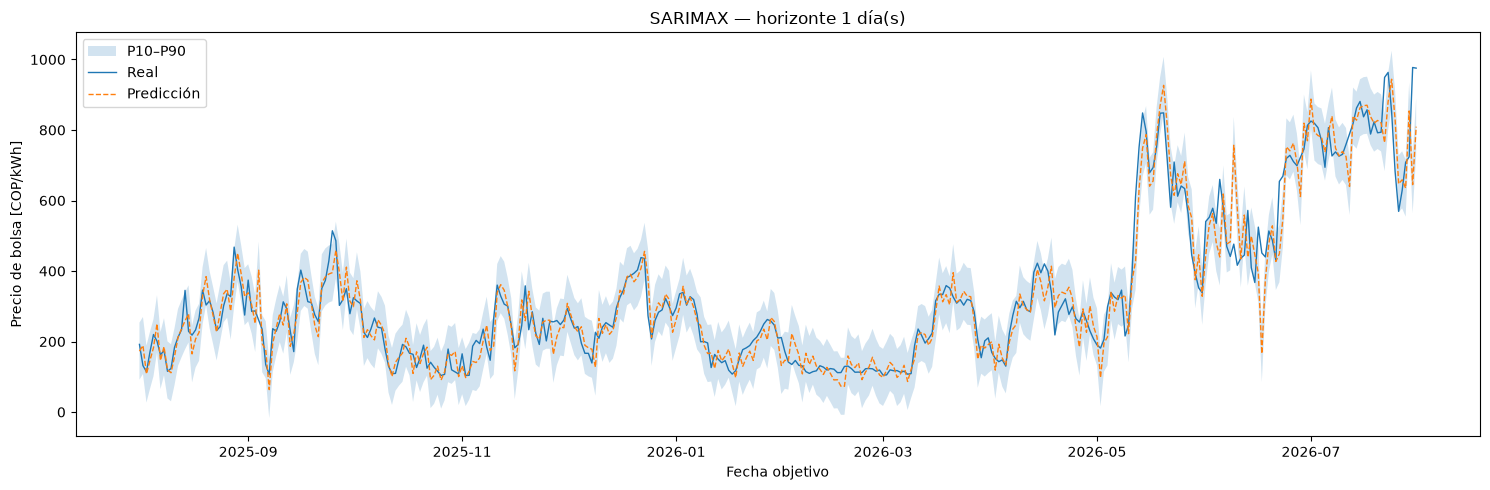

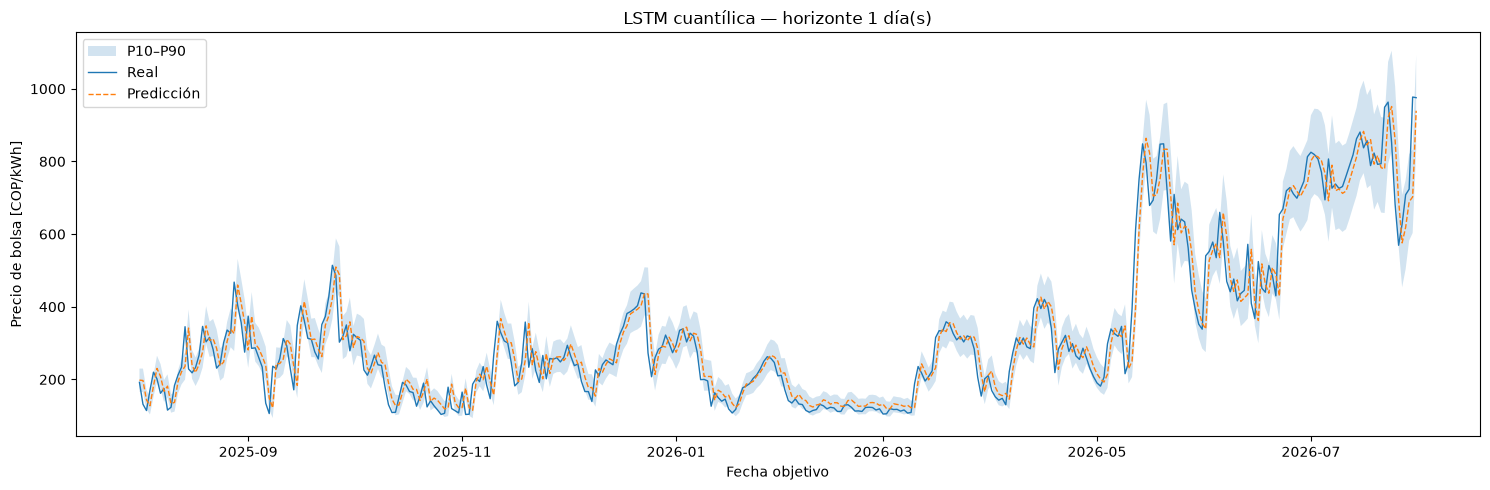

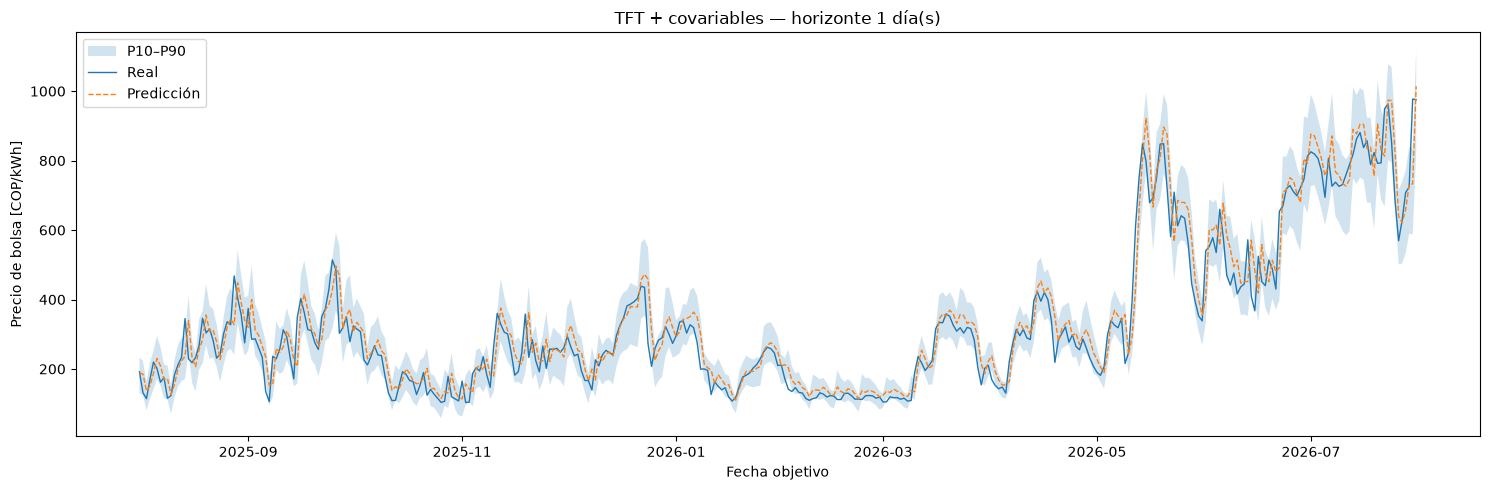

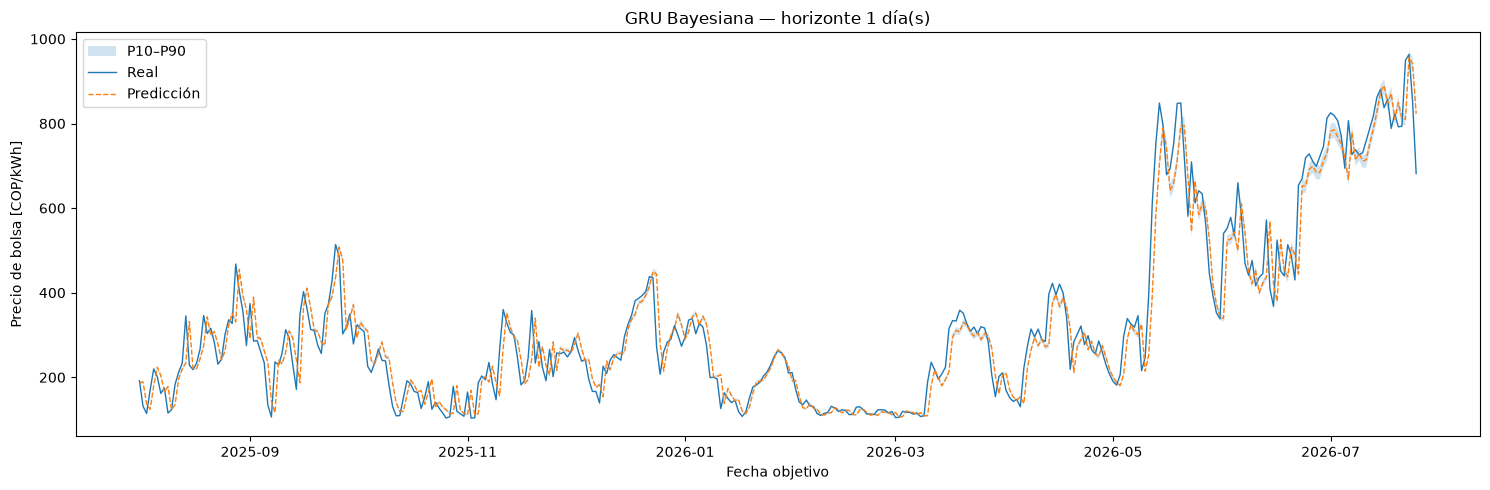

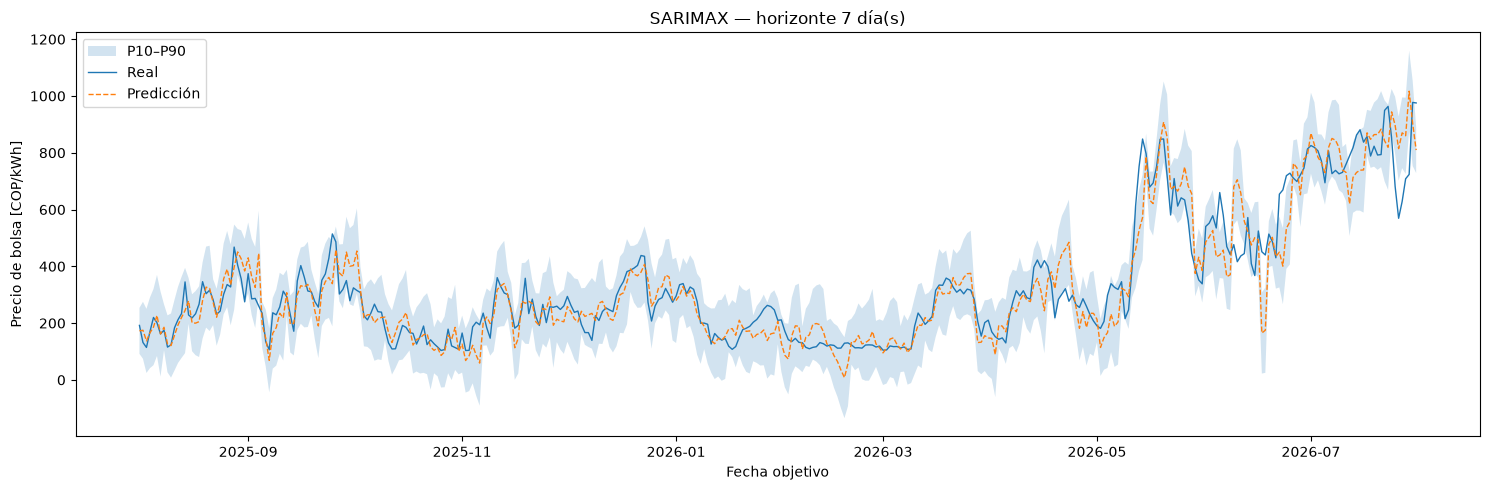

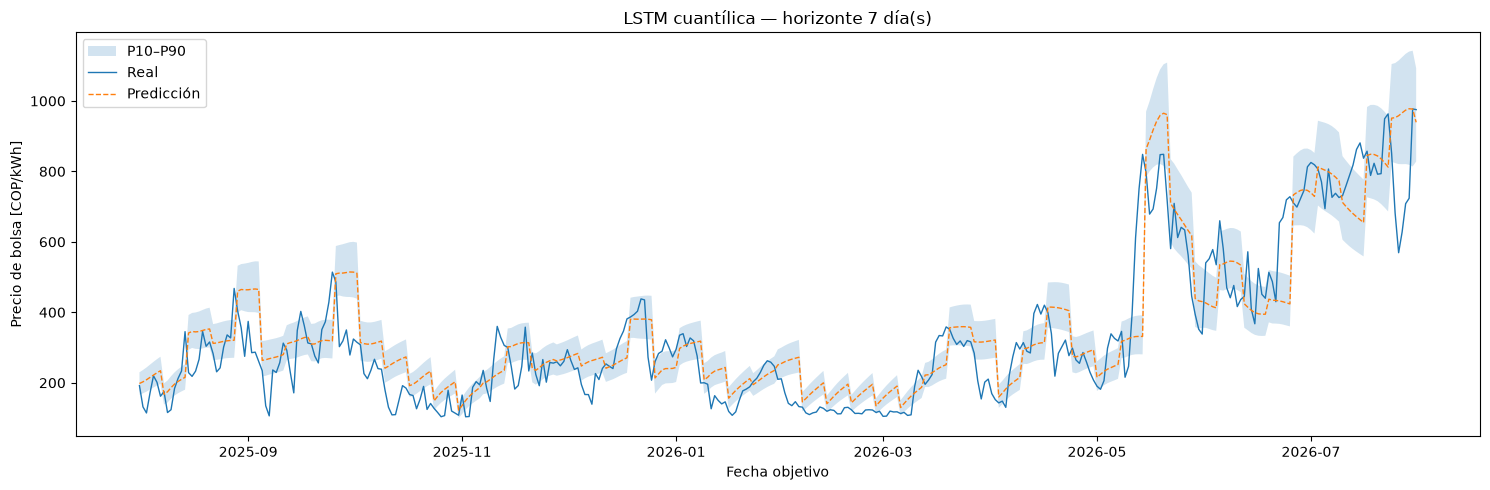

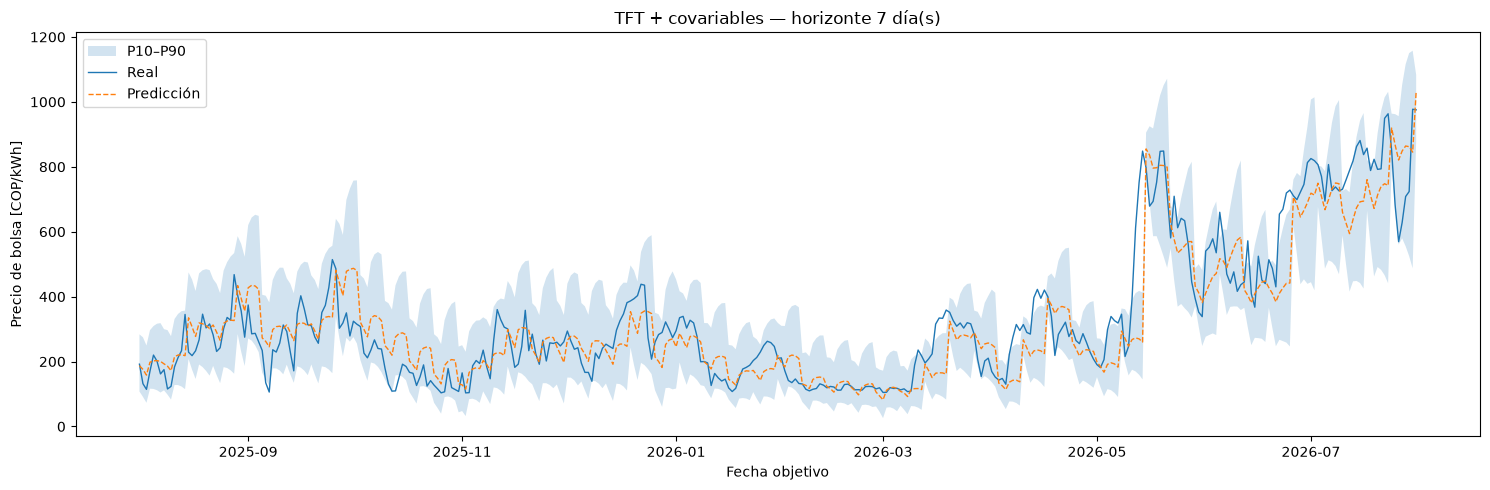

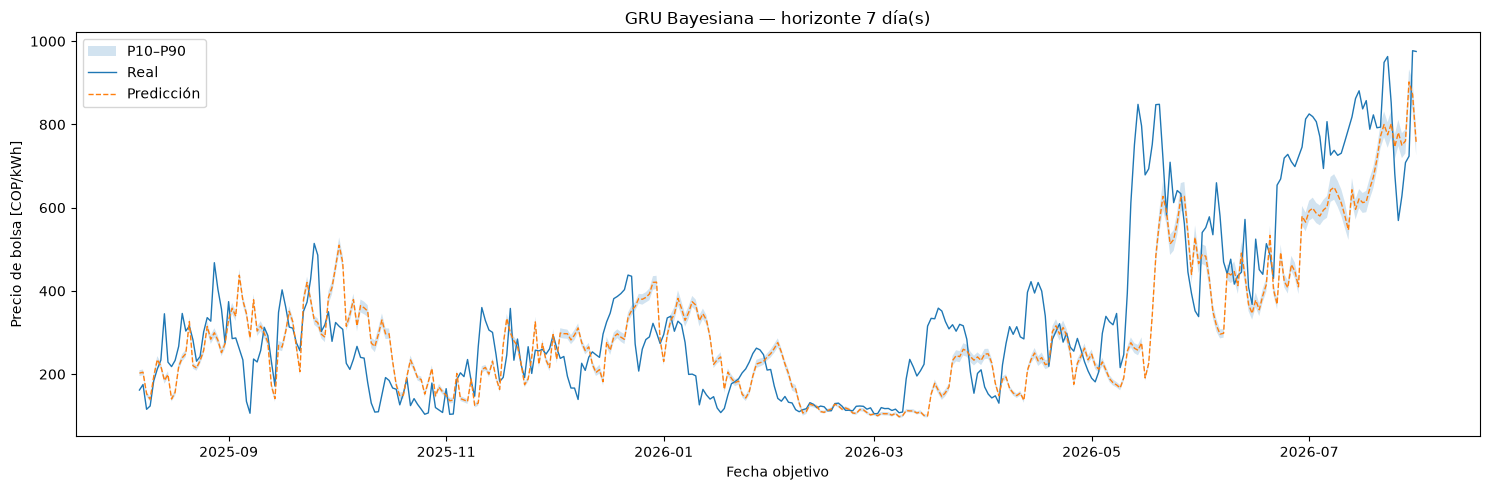

In [24]:
for h in HORIZONTES:
    for modelo in ["SARIMAX","LSTM cuantílica","TFT + covariables","GRU Bayesiana"]:
        key=(modelo,h)
        if key not in resultados:
            continue
        z=resultados[key]
        plt.figure(figsize=(15,5))
        plt.fill_between(z.index,z.p10,z.p90,alpha=.20,label="P10–P90")
        plt.plot(z.index,z.real,label="Real",linewidth=1)
        plt.plot(z.index,z.pred,"--",label="Predicción",linewidth=1)
        plt.title(f"{modelo} — horizonte {h} día(s)")
        plt.ylabel("Precio de bolsa [COP/kWh]")
        plt.xlabel("Fecha objetivo")
        plt.legend()
        plt.tight_layout()
        plt.show()

## 9. Comparación puntual conjunta

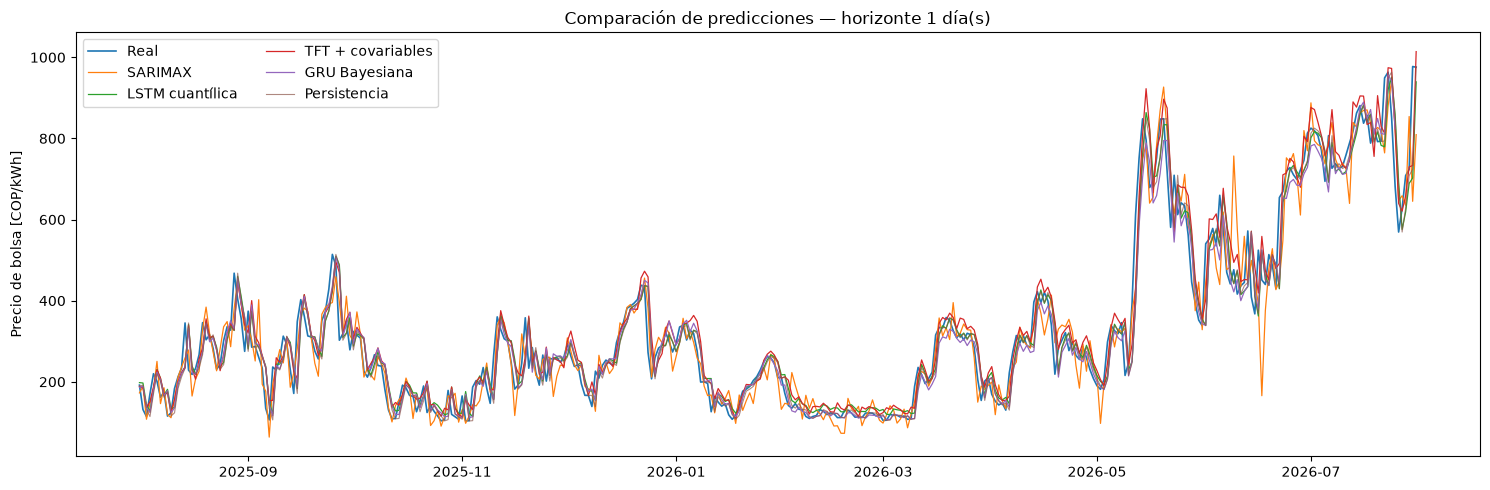

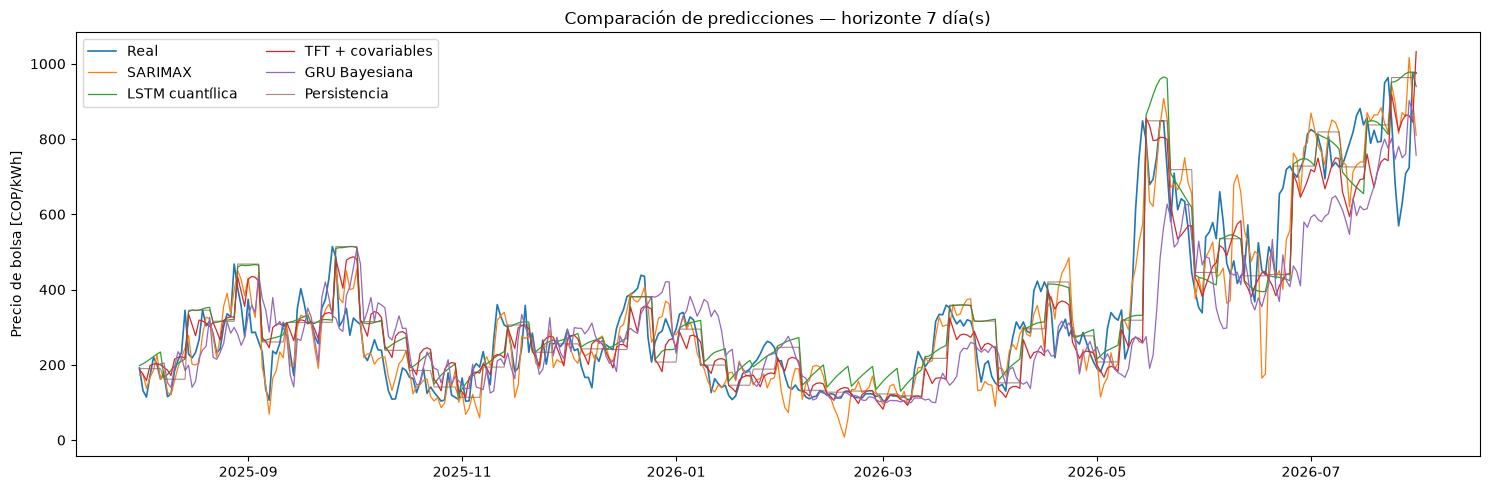

In [25]:
for h in HORIZONTES:
    plt.figure(figsize=(15,5))
    plt.plot(test_data.index,test_data.precio_bolsa if hasattr(test_data,'precio_bolsa') else test_data,
             label="Real",linewidth=1.2)
    for modelo in ["SARIMAX","LSTM cuantílica","TFT + covariables","GRU Bayesiana"]:
        if (modelo,h) in resultados:
            z=resultados[(modelo,h)]
            plt.plot(z.index,z.pred,label=modelo,linewidth=.9)
    p=persistencia[h]
    plt.plot(p.index,p.values,label="Persistencia",linewidth=.8,alpha=.7)
    plt.title(f"Comparación de predicciones — horizonte {h} día(s)")
    plt.ylabel("Precio de bolsa [COP/kWh]")
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.show()

## 10. Calibración UCT

In [27]:
if UCT_OK:
    for h in HORIZONTES:
        for modelo in ["SARIMAX","LSTM cuantílica","TFT + covariables","GRU Bayesiana"]:
            if (modelo,h) not in resultados:
                continue
            z=resultados[(modelo,h)]
            try:
                uct.viz.plot_calibration(
                    z.pred.to_numpy(),z["std"].to_numpy(),z.real.to_numpy()
                )
                plt.title(f"Calibración UCT — {modelo} — h={h}")
                plt.tight_layout()
                plt.show()
            except Exception as e:
                print(f"No se pudo dibujar calibración {modelo} h={h}: {e}")
else:
    print("Instala uncertainty-toolbox para generar estas gráficas.")

Instala uncertainty-toolbox para generar estas gráficas.


## 11. Rankings y exportación

In [28]:
cols_punt = [
    "Modelo", "Horizonte", "MAE", "RMSE", "MAPE (%)",
    "sMAPE (%)", "R²", "Sesgo"
]

cols_prob = [
    "Modelo", "Horizonte",
    "Cobertura 80% (%)",
    "Ancho P10-P90",
    "Interval score 80%",
    "MACE",
    "RMSCE",
    "Miscalibration area",
    "Sharpness UCT",
    "CRPS",
    "NLL"
]

# ============================================================
# Ranking puntual
# ============================================================

print("RANKING PUNTUAL")

tabla_puntual = tabla_final[
    [c for c in cols_punt if c in tabla_final.columns]
].copy()

tabla_puntual = tabla_puntual.sort_values(
    ["Horizonte", "RMSE"]
)

display(tabla_puntual.round(4))


# ============================================================
# Diagnóstico probabilístico
# ============================================================

print("\nRANKING / DIAGNÓSTICO PROBABILÍSTICO")

prob = tabla_final[
    tabla_final["Modelo"] != "Persistencia"
].copy()

columnas_prob_disponibles = [
    c for c in cols_prob if c in prob.columns
]

tabla_prob = prob[columnas_prob_disponibles].copy()

# Ordenar por CRPS solo si realmente existe.
# Si no existe, usar Interval Score, que sí calculamos directamente.
if "CRPS" in tabla_prob.columns:
    criterio_prob = "CRPS"
elif "Interval score 80%" in tabla_prob.columns:
    criterio_prob = "Interval score 80%"
else:
    criterio_prob = None

if criterio_prob is not None:
    tabla_prob = tabla_prob.sort_values(
        ["Horizonte", criterio_prob],
        na_position="last"
    )
else:
    tabla_prob = tabla_prob.sort_values("Horizonte")

display(tabla_prob.round(4))


# ============================================================
# Exportación
# ============================================================

tabla_final.to_csv(
    REPORTS / "tabla_comparativa_probabilistica.csv",
    index=False
)

tabla_final.to_parquet(
    REPORTS / "tabla_comparativa_probabilistica.parquet",
    index=False
)

for (modelo, h), z in resultados.items():
    nombre = (
        modelo.lower()
        .replace(" ", "_")
        .replace("+", "mas")
    )

    z.to_parquet(
        REPORTS / f"pred_{nombre}_h{h}.parquet"
    )

print("\nResultados guardados en:")
print(REPORTS)

RANKING PUNTUAL


,Modelo,Horizonte,MAE,RMSE,MAPE (%),sMAPE (%),R²,Sesgo
6,GRU Bayesiana,1,38.0371,55.2477,13.1724,13.0061,0.9272,-4.6650
4,TFT + covariables,1,40.7515,56.1886,14.6050,13.6043,0.9295,15.4877
8,Persistencia,1,40.2637,58.3728,13.6798,13.6093,0.9239,-2.1524
2,LSTM cuantílica,1,41.4749,58.5284,14.7928,14.2309,0.9235,2.3017
0,SARIMAX,1,40.3002,58.9207,14.0298,14.0870,0.9225,-2.9430
1,SARIMAX,7,56.6495,79.2690,19.2326,19.7362,0.8597,-4.3724
5,TFT + covariables,7,69.0731,96.3933,23.3898,22.5336,0.7925,-10.3363
9,Persistencia,7,70.4732,99.7142,24.3975,22.5046,0.7780,11.5427
3,LSTM cuantílica,7,74.6741,101.4309,28.5615,24.4601,0.7703,24.3602
7,GRU Bayesiana,7,94.4610,130.5779,30.6507,29.8153,0.6218,-33.2098



RANKING / DIAGNÓSTICO PROBABILÍSTICO


,Modelo,Horizonte,Cobertura 80% (%),Ancho P10-P90,Interval score 80%
4,TFT + covariables,1,82.1918,135.2072,181.6660
2,LSTM cuantílica,1,71.5068,110.3211,212.2148
0,SARIMAX,1,87.9452,161.8360,221.6224
6,GRU Bayesiana,1,14.2061,12.9588,333.6725
1,SARIMAX,7,91.2329,241.3950,300.8122
5,TFT + covariables,7,88.4932,268.8432,332.2491
3,LSTM cuantílica,7,44.6575,116.4981,434.1259
7,GRU Bayesiana,7,7.7994,24.9711,848.1078



Resultados guardados en:
/Users/maguverm/Documents/tesis-bolsa/reports/comparacion_probabilistica


## Lectura recomendada para la tesis

La comparación debe separar dos preguntas:

1. **¿Qué modelo predice mejor el nivel del precio?**  
   Se responde con MAE, RMSE, MAPE, sMAPE y R², contrastando además con Persistencia.

2. **¿Qué modelo representa mejor su propia incertidumbre?**  
   Se responde con cobertura, ancho de P10–P90, calibración, sharpness y proper scoring rules.

Un modelo probabilístico no debe considerarse superior solo por producir bandas. Una banda útil debe ser simultáneamente **razonablemente calibrada y suficientemente estrecha**, manteniendo buena precisión puntual.

### Origen de la incertidumbre
- SARIMAX: distribución predictiva del modelo state-space.
- LSTM: cuantiles aprendidos por pinball loss.
- TFT + covariables: cuantiles probabilísticos nativos de GluonTS.
- GRU Bayesiana: variabilidad empírica de múltiples forward passes con pesos bayesianos muestreados.